# CALOR Y MAYORES EN MADRID

## Modelo: predicción de la temperatura de superficie a partir de la forma urbana

**Target:** temperatura de superficie de verano (lst) de cada hexágono urbano.
**Features:** 14 variables de vegetación, edificación, terreno y entorno (seleccionadas en el EDA).
**Validación:** espacial, por distritos, para evitar que el modelo copie a los hexágonos vecinos.

- Test: apartamos distritos completos (un 20 % de los 21, unos 4) que el modelo nunca verá al entrenar. Es la evaluación honesta: así medimos si el modelo funciona en zonas nuevas, sin copiar a los hexágonos vecinos.
- Train: con los distritos restantes, compararemos y ajustaremos los modelos con validación cruzada agrupada por distrito.

## 1. Preparación de los datos 
 - importamos las librerías

In [18]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib
import shap

sys.path.append("../scrips")
from config import RUTA_RAW, RUTA_CLEAN

- cargamos los hexágonos urbanos y definimos target y features

In [2]:
hexagonos_todos = gpd.read_file(RUTA_CLEAN + "hexagonos_h3.gpkg")
hexagonos = hexagonos_todos[hexagonos_todos["urbano"]].copy()

target = "lst"
features = ["ndvi", "albedo", "pct_edificado", "pct_industrial", "plantas_media",
            "anio_medio", "pct_copa", "altura_arboles", "arboles_ha", "elevacion",
            "dist_parque_grande", "pct_viario", "dist_agua", "pct_suelo_desnudo"]
print(hexagonos.shape)
print("Features:", len(features))

(2931, 21)
Features: 14


- asignamos a cada hexágono su distrito (por la posición de su centro)

In [3]:
distritos = gpd.read_file(RUTA_RAW + "limites/Distritos/DISTRITOS.shp")
centroides = hexagonos.copy()
centroides["geometry"] = hexagonos.centroid
hexagonos_distrito = gpd.sjoin_nearest(centroides, distritos[["NOMBRE", "geometry"]], how="left")
hexagonos_distrito = hexagonos_distrito[~hexagonos_distrito.index.duplicated()]
hexagonos["distrito"] = hexagonos_distrito["NOMBRE"]

print("Sin distrito:", hexagonos["distrito"].isnull().sum())
hexagonos["distrito"].value_counts()

Sin distrito: 0


distrito
Moncloa - Aravaca        407
Barajas                  347
Fuencarral - El Pardo    249
Hortaleza                222
Vicálvaro                218
Villa de Vallecas        208
Latina                   157
San Blas - Canillejas    150
Villaverde               142
Carabanchel              123
Puente de Vallecas       113
Ciudad Lineal            101
Chamartín                 79
Usera                     69
Arganzuela                55
Moratalaz                 54
Tetuán                    49
Retiro                    49
Salamanca                 48
Centro                    47
Chamberí                  44
Name: count, dtype: int64

**Observación:** todos los hexágonos tienen distrito; los periféricos (Moncloa-Aravaca, Barajas, Fuencarral) tienen muchos más hexágonos que los centrales (Centro, Chamberí), porque son más extensos.

**Decisión:** a cada hexágono se le asigna el distrito más cercano a su centro, porque un hexágono del borde tiene su centro fuera de los polígonos de distritos. Para el resto el resultado es el mismo, ya que su distrito más cercano es el que lo contiene.

- separamos train y test por distritos completos

In [4]:
separador = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
indices_train, indices_test = next(separador.split(hexagonos, groups=hexagonos["distrito"]))

train = hexagonos.iloc[indices_train].copy()
test = hexagonos.iloc[indices_test].copy()

print("Train:", train.shape, "- Test:", test.shape)
print("Distritos de test:", sorted(test["distrito"].unique()))

Train: (2117, 22) - Test: (814, 22)
Distritos de test: ['Barajas', 'Hortaleza', 'Moratalaz', 'Retiro', 'Villaverde']


**Observación:** el test lo forman 5 distritos completos (Barajas, Hortaleza, Moratalaz, Retiro y Villaverde), con 814 hexágonos (28 %); el train, los 16 restantes, con 2.117. El test es variado: centro (Retiro), periferia residencial (Hortaleza, Moratalaz), sur industrial (Villaverde) y el aeropuerto (Barajas).

**Decisión:** los nulos se rellenan como en el EDA (`plantas_media` y `altura_arboles` con 0), pero la mediana de `anio_medio` se calcula solo con train, para que el test no influya en el entrenamiento.

- rellenamos los nulos

In [5]:
mediana_anio_train = train["anio_medio"].median()
for tabla in [train, test]:
    tabla["plantas_media"] = tabla["plantas_media"].fillna(0)
    tabla["altura_arboles"] = tabla["altura_arboles"].fillna(0)
    tabla["anio_medio"] = tabla["anio_medio"].fillna(mediana_anio_train)

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
grupos_train = train["distrito"]

print("Mediana del año (train):", mediana_anio_train)
print("Nulos en X_train:", X_train.isnull().sum().sum(), "- en X_test:", X_test.isnull().sum().sum())

Mediana del año (train): 1978.0
Nulos en X_train: 0 - en X_test: 0


**Observación:** la mediana del año calculada solo con train es 1978; no quedan nulos en train ni en test.

## 2. Ronda 1: comparación de 11 modelos con su configuración por defecto

**Decisión:** los modelos se comparan y el mejor se ajusta solo con validación cruzada agrupada por distritos dentro de train. El test (5 distritos) se usa una única vez al final, con el modelo elegido, para que su evaluación sea independiente de todas las decisiones tomadas.

- definimos la validación cruzada agrupada, las métricas y los 11 modelos

In [6]:
validacion = GroupKFold(n_splits=5)

metricas = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

modelos = {
    "Regresión lineal": LinearRegression(),
    "Ridge": Pipeline([("escalado", StandardScaler()), ("modelo", Ridge(random_state=0))]),
    "Lasso": Pipeline([("escalado", StandardScaler()), ("modelo", Lasso(random_state=0))]),
    "KNN": Pipeline([("escalado", StandardScaler()), ("modelo", KNeighborsRegressor())]),
    "SVR": Pipeline([("escalado", StandardScaler()), ("modelo", SVR())]),
    "Árbol de decisión": DecisionTreeRegressor(random_state=0),
    "Random Forest": RandomForestRegressor(random_state=0, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(random_state=0, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=0),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=0),
    "XGBoost": XGBRegressor(random_state=0, n_jobs=-1)
}

- evaluamos cada modelo con la validación cruzada

In [7]:
resultados = []
for nombre, modelo in modelos.items():
    puntuaciones = cross_validate(modelo, X_train, y_train, groups=grupos_train, cv=validacion, scoring=metricas)
    resultados.append({
        "modelo": nombre,
        "r2_media": puntuaciones["test_r2"].mean(),
        "r2_desviacion": puntuaciones["test_r2"].std(),
        "mae_media": -puntuaciones["test_mae"].mean(),
        "rmse_media": -puntuaciones["test_rmse"].mean()
    })

tabla_cv = pd.DataFrame(resultados).round(3).sort_values("r2_media", ascending=False)
tabla_cv

,modelo,r2_media,r2_desviacion,mae_media,rmse_media
8,Gradient Boosting,0.654,0.083,0.979,1.319
7,Extra Trees,0.651,0.079,0.986,1.336
6,Random Forest,0.649,0.082,0.981,1.332
9,HistGradientBoosting,0.647,0.087,0.979,1.332
10,XGBoost,0.611,0.070,1.039,1.408
0,Regresión lineal,0.608,0.104,1.049,1.400
1,Ridge,0.608,0.105,1.049,1.401
4,SVR,0.544,0.203,1.094,1.506
3,KNN,0.429,0.195,1.283,1.691
5,Árbol de decisión,0.342,0.154,1.373,1.814


1. Gradient Boosting, Extra Trees, Random Forest e HistGradientBoosting (0,65): combinan muchos árboles y captan las relaciones no lineales y los umbrales (por ejemplo, el suelo desnudo al 100 %). Las diferencias entre ellos (menos de 0,01) son mucho menores que su desviación (0,08): en la práctica están empatados.
2. XGBoost (0,61): con los valores por defecto aprende demasiado rápido y sobreajusta; es el que más suele mejorar con el ajuste.
3. Regresión lineal y Ridge (0,61): casi iguales, porque con 14 features y 2.000 filas la penalización de Ridge apenas cambia nada.
4. SVR (0,54) y KNN (0,43): sensibles a la elección de sus parámetros y con mucha desviación (0,20): funcionan bien en unos distritos y mal en otros.
5. Árbol de decisión (0,34): un solo árbol sin límite de profundidad memoriza train y generaliza mal; por eso se usan conjuntos.
6. Lasso (0,01): con su penalización por defecto (alpha=1) y las features estandarizadas, lleva casi todos los coeficientes a 0 y predice prácticamente la media. No significa que Lasso no sirva, sino que su configuración por defecto es inadecuada aquí.

**Decisión:** pasan a la ronda 2 los 6 mejores modelos: Gradient Boosting, Extra Trees, Random Forest, HistGradientBoosting, XGBoost y Ridge. Ridge ocupa el sexto puesto, empatado con la regresión lineal (R² = 0,608), porque tiene un hiperparámetro que ajustar (alpha) y la regresión lineal no. Los cuatro primeros están prácticamente empatados (diferencias menores que su desviación), por lo que el ajuste puede cambiar el orden.

## 3. Ronda 2: búsqueda aleatoria de hiperparámetros con rangos

**Decisión:** pasan a la ronda 2 los 6 mejores modelos: Gradient Boosting, Extra Trees, Random Forest, HistGradientBoosting, XGBoost y Ridge. Ridge ocupa el sexto puesto, empatado con la regresión lineal (R² = 0,608), porque tiene un hiperparámetro que ajustar (alpha) y la regresión lineal no. Los cuatro primeros están prácticamente empatados, por lo que el ajuste puede cambiar el orden.

**Decisión:** se prueban 100 combinaciones por modelo (50 en Ridge, que solo tiene un hiperparámetro). Con unas 60 combinaciones la búsqueda aleatoria ya encuentra con alta probabilidad una configuración entre el 5 % mejor (Bergstra y Bengio, 2012), y la ronda 3 refinará los mejores valores.

- definimos cada modelo con sus rangos de hiperparámetros

In [8]:
profundidades_arbol = [None] + list(range(5, 41))

busquedas = {
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=0),
        {"n_estimators": randint(100, 1001),
         "learning_rate": loguniform(0.005, 0.3),
         "max_depth": randint(2, 9),
         "min_samples_leaf": randint(1, 21),
         "subsample": uniform(0.6, 0.4)},
        100),
    "Extra Trees": (
        ExtraTreesRegressor(random_state=0, n_jobs=1),
        {"n_estimators": randint(100, 1001),
         "max_depth": profundidades_arbol,
         "min_samples_split": randint(2, 21),
         "min_samples_leaf": randint(1, 16),
         "max_features": uniform(0.3, 0.7)},
        100),
    "Random Forest": (
        RandomForestRegressor(random_state=0, n_jobs=1),
        {"n_estimators": randint(100, 1001),
         "max_depth": profundidades_arbol,
         "min_samples_split": randint(2, 21),
         "min_samples_leaf": randint(1, 16),
         "max_features": uniform(0.3, 0.7)},
        100),
    "HistGradientBoosting": (
        HistGradientBoostingRegressor(random_state=0),
        {"max_iter": randint(100, 1001),
         "learning_rate": loguniform(0.005, 0.3),
         "max_depth": [None] + list(range(3, 11)),
         "min_samples_leaf": randint(5, 51),
         "l2_regularization": loguniform(0.0001, 10)},
        100),
    "XGBoost": (
        XGBRegressor(random_state=0, n_jobs=1),
        {"n_estimators": randint(100, 1001),
         "learning_rate": loguniform(0.005, 0.3),
         "max_depth": randint(2, 11),
         "min_child_weight": randint(1, 16),
         "subsample": uniform(0.6, 0.4),
         "colsample_bytree": uniform(0.5, 0.5),
         "reg_lambda": loguniform(0.001, 10)},
        100),
    "Ridge": (
        Pipeline([("escalado", StandardScaler()), ("modelo", Ridge(random_state=0))]),
        {"modelo__alpha": loguniform(0.001, 1000)},
        50)
}

- ejecutamos la búsqueda de cada modelo y guardamos sus mejores resultados

In [9]:
resultados_ronda2 = []
mejores_busquedas = {}

for nombre, (modelo, parametros, n_combinaciones) in busquedas.items():
    busqueda = RandomizedSearchCV(
        modelo,
        param_distributions=parametros,
        n_iter=n_combinaciones,
        scoring=metricas,
        refit="r2",
        cv=validacion,
        random_state=0,
        n_jobs=-1
    )
    busqueda.fit(X_train, y_train, groups=grupos_train)
    mejores_busquedas[nombre] = busqueda

    i = busqueda.best_index_
    resultados_ronda2.append({
        "modelo": nombre,
        "r2_media": busqueda.cv_results_["mean_test_r2"][i],
        "r2_desviacion": busqueda.cv_results_["std_test_r2"][i],
        "mae_media": -busqueda.cv_results_["mean_test_mae"][i],
        "rmse_media": -busqueda.cv_results_["mean_test_rmse"][i]
    })
    print(f"{nombre}: R² = {busqueda.best_score_:.3f}")

tabla_ronda2 = pd.DataFrame(resultados_ronda2).round(3).sort_values("r2_media", ascending=False)
tabla_ronda2

Gradient Boosting: R² = 0.680
Extra Trees: R² = 0.656
Random Forest: R² = 0.647
HistGradientBoosting: R² = 0.663
XGBoost: R² = 0.674
Ridge: R² = 0.608


,modelo,r2_media,r2_desviacion,mae_media,rmse_media
0,Gradient Boosting,0.680,0.065,0.939,1.274
4,XGBoost,0.674,0.060,0.955,1.290
3,HistGradientBoosting,0.663,0.077,0.984,1.306
1,Extra Trees,0.656,0.078,0.978,1.323
2,Random Forest,0.647,0.097,0.991,1.333
5,Ridge,0.608,0.104,1.049,1.400


- mejores hiperparámetros de cada modelo

In [10]:
for nombre, busqueda in mejores_busquedas.items():
    print(nombre, busqueda.best_params_)

Gradient Boosting {'learning_rate': np.float64(0.08676339177635921), 'max_depth': 2, 'min_samples_leaf': 6, 'n_estimators': 447, 'subsample': np.float64(0.7037690257381419)}
Extra Trees {'max_depth': 15, 'max_features': np.float64(0.8896394557674117), 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 282}
Random Forest {'max_depth': 25, 'max_features': np.float64(0.8249994741390703), 'min_samples_leaf': 3, 'min_samples_split': 4, 'n_estimators': 188}
HistGradientBoosting {'l2_regularization': np.float64(0.003624942344480169), 'learning_rate': np.float64(0.028542183144880814), 'max_depth': 3, 'max_iter': 220, 'min_samples_leaf': 5}
XGBoost {'colsample_bytree': np.float64(0.6790537375575612), 'learning_rate': np.float64(0.024209197967180032), 'max_depth': 4, 'min_child_weight': 4, 'n_estimators': 699, 'reg_lambda': np.float64(3.3641925856077384), 'subsample': np.float64(0.708974758186385)}
Ridge {'modelo__alpha': np.float64(0.0012963993440545018)}


## 4. Ronda 3: búsqueda fina de hiperparámetros

**Decisión:** pasan a la ronda 3 los 3 mejores modelos de la ronda 2: Gradient Boosting (R² = 0,680), XGBoost (0,674) e HistGradientBoosting (0,663), los tres de boosting y con la menor desviación entre distritos.

**Decisión:** se prueba una cuadrícula estrecha alrededor de los mejores valores de la ronda 2 (un valor por debajo, el mejor y uno por encima). Los hiperparámetros menos influyentes se fijan en su mejor valor (redondeado) para limitar el número de combinaciones.

- definimos cada modelo con su cuadrícula

In [11]:
cuadriculas = {
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=0),
        {"learning_rate": [0.06, 0.087, 0.11],
         "max_depth": [2, 3],
         "min_samples_leaf": [4, 6, 8],
         "n_estimators": [350, 450, 550],
         "subsample": [0.65, 0.70, 0.75]}),
    "XGBoost": (
        XGBRegressor(random_state=0, n_jobs=1, colsample_bytree=0.68, reg_lambda=3.36),
        {"learning_rate": [0.018, 0.024, 0.030],
         "max_depth": [3, 4, 5],
         "min_child_weight": [3, 4, 5],
         "n_estimators": [600, 700, 800],
         "subsample": [0.65, 0.70, 0.75]}),
    "HistGradientBoosting": (
        HistGradientBoostingRegressor(random_state=0, l2_regularization=0.0036),
        {"learning_rate": [0.020, 0.0285, 0.035],
         "max_depth": [2, 3, 4],
         "max_iter": [180, 220, 260],
         "min_samples_leaf": [3, 5, 8]})
}

- ejecutamos la búsqueda de cada modelo y guardamos sus mejores resultados

In [12]:
resultados_ronda3 = []
busquedas_finales = {}

for nombre, (modelo, cuadricula) in cuadriculas.items():
    busqueda = GridSearchCV(
        modelo,
        param_grid=cuadricula,
        scoring=metricas,
        refit="r2",
        cv=validacion,
        n_jobs=-1
    )
    busqueda.fit(X_train, y_train, groups=grupos_train)
    busquedas_finales[nombre] = busqueda

    i = busqueda.best_index_
    resultados_ronda3.append({
        "modelo": nombre,
        "r2_media": busqueda.cv_results_["mean_test_r2"][i],
        "r2_desviacion": busqueda.cv_results_["std_test_r2"][i],
        "mae_media": -busqueda.cv_results_["mean_test_mae"][i],
        "rmse_media": -busqueda.cv_results_["mean_test_rmse"][i]
    })
    print(f"{nombre}: R² = {busqueda.best_score_:.3f}")

tabla_ronda3 = pd.DataFrame(resultados_ronda3).round(3).sort_values("r2_media", ascending=False)
tabla_ronda3

Gradient Boosting: R² = 0.684
XGBoost: R² = 0.678
HistGradientBoosting: R² = 0.666


,modelo,r2_media,r2_desviacion,mae_media,rmse_media
0,Gradient Boosting,0.684,0.066,0.940,1.264
1,XGBoost,0.678,0.059,0.950,1.282
2,HistGradientBoosting,0.666,0.077,0.972,1.298


- mejores hiperparámetros de cada modelo

In [13]:
for nombre, busqueda in busquedas_finales.items():
    print(nombre, busqueda.best_params_)

Gradient Boosting {'learning_rate': 0.06, 'max_depth': 2, 'min_samples_leaf': 4, 'n_estimators': 550, 'subsample': 0.65}
XGBoost {'learning_rate': 0.024, 'max_depth': 4, 'min_child_weight': 4, 'n_estimators': 700, 'subsample': 0.65}
HistGradientBoosting {'learning_rate': 0.035, 'max_depth': 3, 'max_iter': 260, 'min_samples_leaf': 5}


## 5. Modelo final y evaluación en test

**Decisión:** se elige Gradient Boosting como modelo final: tiene el mejor R² medio en la validación por distritos (0,684) y es el más sencillo de los tres (árboles de profundidad 2). Su diferencia con XGBoost (0,006) es menor que la desviación entre distritos, así que ambos son equivalentes en rendimiento; se prefiere el más simple.

**Mejoras pendientes si hay tiempo:** variables de contexto (media de las features en los hexágonos vecinos) y ampliar la cuadrícula en los valores que quedaron en el borde.

- evaluamos el modelo final una única vez en test (5 distritos que el modelo no ha visto)

In [14]:
modelo_final = busquedas_finales["Gradient Boosting"].best_estimator_
y_pred = modelo_final.predict(X_test)

print("R² test:  ", round(r2_score(y_test, y_pred), 3))
print("MAE test: ", round(mean_absolute_error(y_test, y_pred), 3), "°C")
print("RMSE test:", round(float(np.sqrt(mean_squared_error(y_test, y_pred))), 3), "°C")

R² test:   0.819
MAE test:  1.028 °C
RMSE test: 1.427 °C


- revisamos el error por distrito de test

In [15]:
test["prediccion"] = y_pred
test["error_absoluto"] = (test[target] - test["prediccion"]).abs()
test.groupby("distrito").agg(
    hexagonos=(target, "size"),
    mae=("error_absoluto", "mean"),
    temperatura_media=(target, "mean")
).round(2)

,hexagonos,mae,temperatura_media
distrito,,,
Barajas,347,1.29,48.18
Hortaleza,222,0.89,44.68
Moratalaz,54,0.69,43.58
Retiro,49,0.67,41.95
Villaverde,142,0.85,46.62


- guardamos el modelo final con lo necesario para usarlo después (lista de features y mediana del año de train)

In [16]:
paquete_modelo = {
    "modelo": modelo_final,
    "features": features,
    "mediana_anio_train": mediana_anio_train
}
joblib.dump(paquete_modelo, "../models/modelo_gradient_boosting.pkl")

['../models/modelo_gradient_boosting.pkl']

## 6. Interpretación del modelo con SHAP

**Qué es:** SHAP (SHapley Additive exPlanations) es un método que reparte la predicción del modelo entre las features. Parte de la temperatura media que predice el modelo (valor base) y calcula cuántos grados suma o resta cada feature en cada hexágono. La suma del valor base y de todos los valores SHAP da exactamente la predicción. Se basa en los valores de Shapley de la teoría de juegos, que reparten de forma justa un resultado entre los miembros de un equipo según lo que aporta cada uno.

**Por qué se usa:** los modelos de árboles como Gradient Boosting predicen bien, pero no muestran directamente cómo llegan al resultado. La importancia de variables del propio modelo solo indica cuánto usa cada feature; SHAP indica además si calienta o enfría, cuánto en grados y en qué hexágono.

**Para qué sirve en el proyecto:**
- Responder a la hipótesis 1: qué features explican más la temperatura de superficie.
- Conocer la forma del efecto de la vegetación, que es la base del simulador de arbolado.
- Explicar por qué el entorno de cada centro de mayores está caliente (por ejemplo, por falta de vegetación o por suelo desnudo cercano), para la ficha de la app.

**Precauciones:** SHAP explica cómo usa el modelo cada feature, no demuestra causas. Las features correlacionadas (como el NDVI y la copa de árboles) se reparten el efecto entre ellas.

- calculamos los valores SHAP del modelo final en los hexágonos de test

In [19]:
explicador = shap.TreeExplainer(modelo_final)
valores_shap = explicador(X_test)

print("Valor base (temperatura media predicha):", round(float(valores_shap.base_values[0]), 2), "°C")
print("Tamaño de los valores SHAP:", valores_shap.values.shape)

Valor base (temperatura media predicha): 44.79 °C
Tamaño de los valores SHAP: (814, 14)


**Observación:** se calculan los valores SHAP de los 814 hexágonos de test y las 14 features; el valor base es de 44,79 °C, la temperatura media que el modelo aprendió en train.

- comprobamos que el valor base más los valores SHAP dan la predicción del modelo

In [20]:
reconstruccion = valores_shap.base_values + valores_shap.values.sum(axis=1)
print("Diferencia máxima con la predicción:", round(float(np.abs(reconstruccion - y_pred).max()), 6), "°C")

Diferencia máxima con la predicción: 0.0 °C


**Observación:** el valor base más la suma de los valores SHAP reproduce exactamente la predicción del modelo en todos los hexágonos (diferencia de 0,0 °C).

- importancia global: para cada feature, la media del valor absoluto de SHAP en todos los hexágonos. Mide cuántos grados mueve esa feature la predicción de media, sin importar si calienta o enfría. Sirve para ordenar las features por su peso en el modelo y responder a la hipótesis 1.

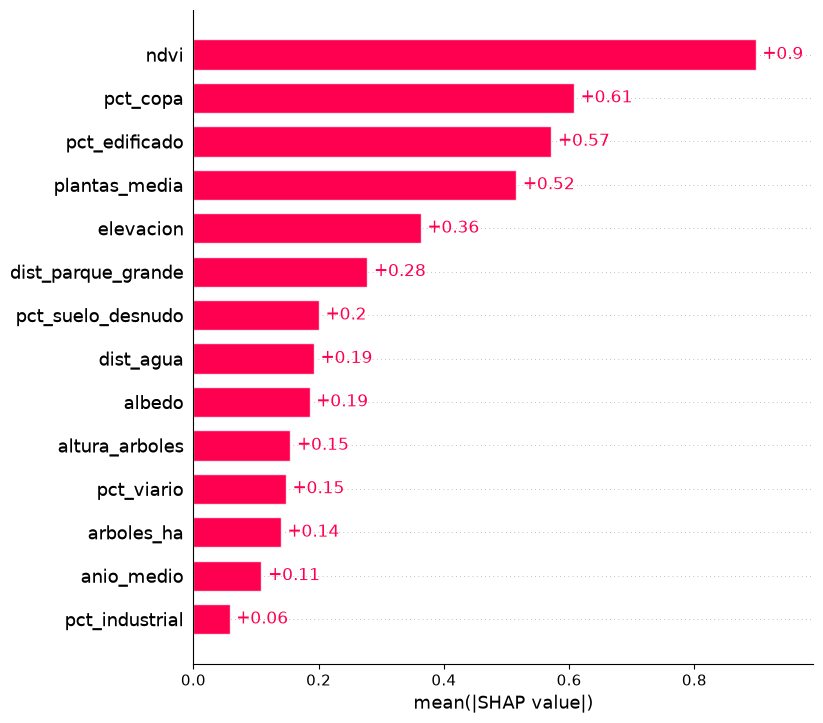

In [21]:
shap.plots.bar(valores_shap, max_display=14)

**Observación:** el NDVI es la feature más importante (mueve la predicción 0,9 °C de media), seguida de la copa de árboles (0,61 °C), el % edificado (0,57 °C) y las plantas (0,52 °C). Sumando el bloque de vegetación (NDVI, copa, altura y densidad de árboles, 1,8 °C) y el de edificación (% edificado, plantas, año e industrial, 1,26 °C), la vegetación y la forma de los edificios son lo que más explica la temperatura, lo que apoya la hipótesis 1.

- Grafico beeswarm: cada punto es un hexágono. La posición horizontal es su valor SHAP (a la derecha calienta, a la izquierda enfría, en °C) y el color es el valor de la feature (rojo alto, azul bajo). Sirve para ver a la vez la importancia y la dirección del efecto de cada feature.

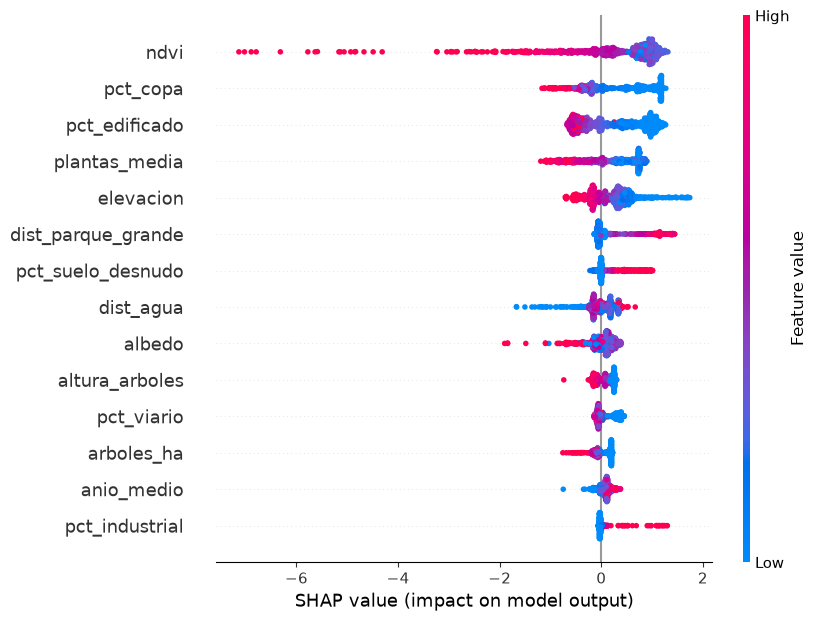

In [22]:
shap.plots.beeswarm(valores_shap, max_display=14)

Observación: mucha vegetación (NDVI y copa altos) enfría hasta 7 °C, mientras que la falta de vegetación calienta en torno a 1 °C. Más edificios, más plantas y más altitud enfrían; la lejanía a un parque grande, el suelo desnudo y el uso industrial calientan.

- scatter: para una feature, cada punto es un hexágono; en el eje horizontal está el valor de la feature y en el vertical su valor SHAP (°C). Muestra la forma del efecto: si es lineal, si tiene un umbral o si se satura. Es la base del simulador de arbolado.

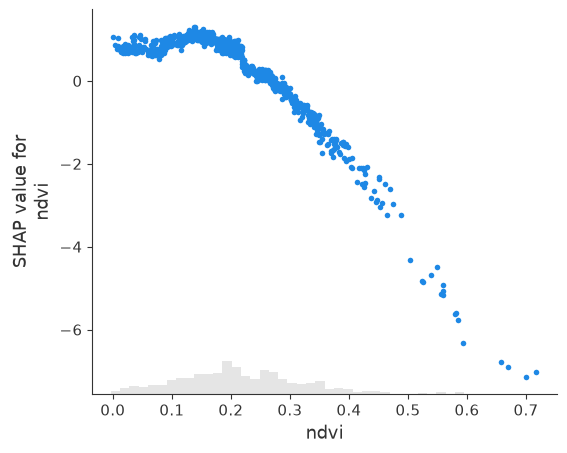

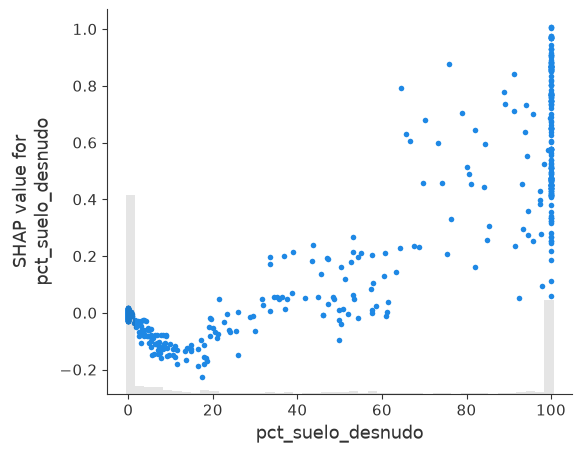

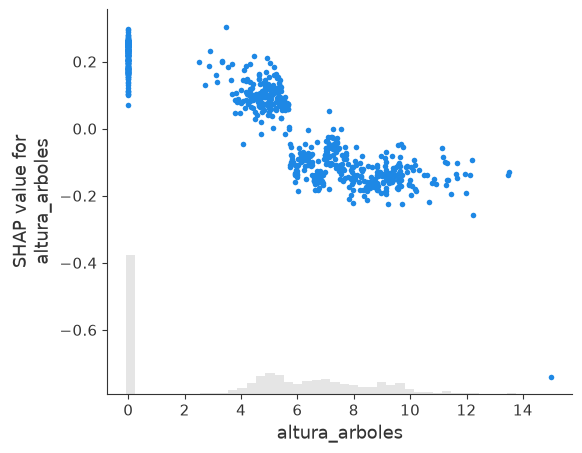

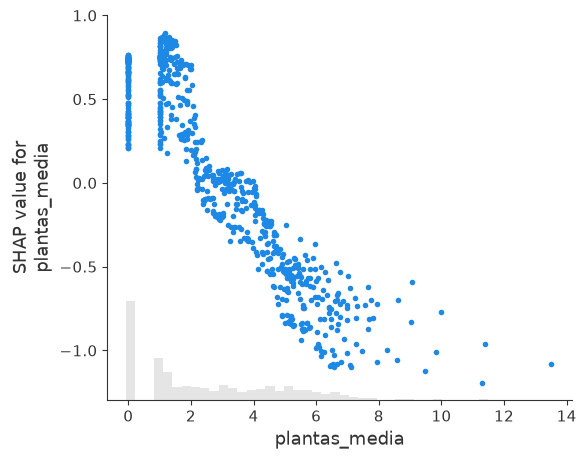

In [23]:
for feature in ["ndvi", "pct_suelo_desnudo", "altura_arboles", "plantas_media"]:
    shap.plots.scatter(valores_shap[:, feature])

**Observación del NDVI:** por debajo de 0,2 de NDVI el efecto es casi constante (calienta en torno a 1 °C); a partir de 0,2 la vegetación empieza a enfriar de forma cada vez más intensa, hasta −3 °C con 0,5 y −7 °C con 0,7 (parques). El efecto no es lineal: plantar en zonas casi sin vegetación apenas cambia la predicción hasta superar ese umbral de 0,2.

**Observación del suelo desnudo:** hasta un 30 % de suelo desnudo apenas influye; a partir de ahí calienta cada vez más, hasta 1 °C cuando el hexágono es todo solar.

**Observación de la altura de los árboles:** sin árboles o con árboles bajos (hasta unos 6 m) el efecto es de calentar ligeramente; los árboles de más de 6 m enfrían. Su efecto es pequeño (unos ±0,3 °C), porque el NDVI y la copa ya recogen buena parte de la vegetación.

**Observación de las plantas:** los hexágonos con edificios de 1-2 plantas son los que más calientan (hasta +0,9 °C, como naves y viviendas bajas con tejados al sol); a partir de 3 plantas el efecto pasa a enfriar, hasta −1 °C con 6-8 plantas, por la sombra que dan los edificios altos.

**Para el simulador:** la curva del NDVI indica dónde una intervención tiene más efecto: en entornos con un NDVI de 0,2-0,3, subirlo 0,1 enfría alrededor de 1 °C según el modelo; en entornos por debajo de 0,15, una subida pequeña apenas se notaría.

- explicación de un hexágono (waterfall): parte del valor base (la temperatura media que predice el modelo, abajo) y suma o resta, feature a feature, hasta llegar a la predicción de ese hexágono (arriba). Sirve para explicar por qué un lugar concreto está caliente o fresco, como se hará en la ficha de cada centro de la app.

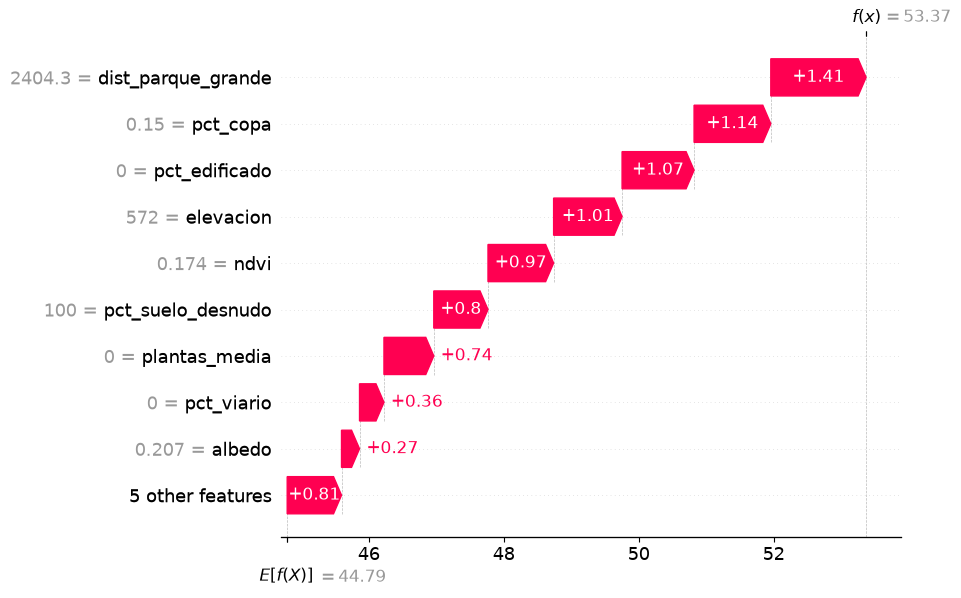

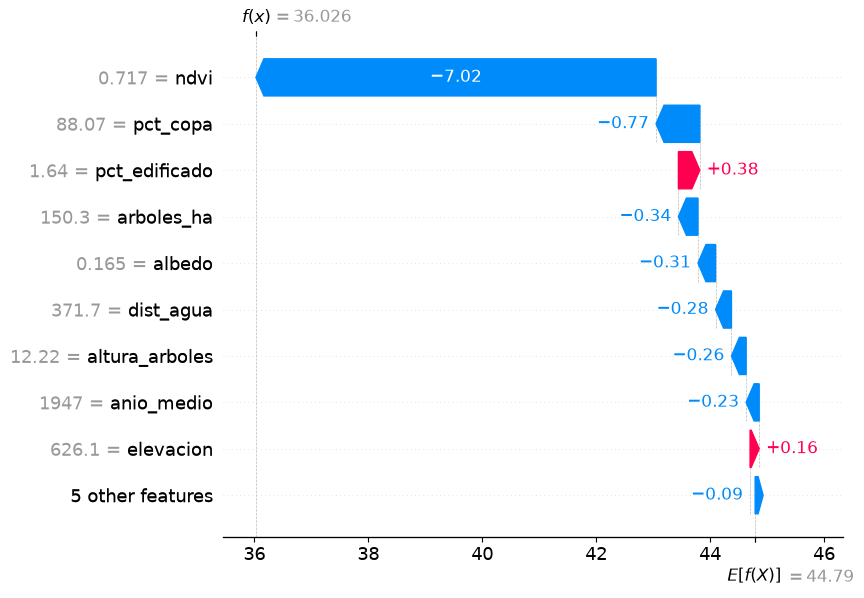

In [24]:
posicion_caliente = int(np.argmax(y_pred))
posicion_fresco = int(np.argmin(y_pred))

shap.plots.waterfall(valores_shap[posicion_caliente], max_display=10)
shap.plots.waterfall(valores_shap[posicion_fresco], max_display=10)

**Observación del hexágono más caliente (53,4 °C):** está 8,6 °C por encima de la media porque se juntan muchos factores: está a 2,4 km del parque grande más cercano (+1,4 °C), casi sin copa de árboles (+1,1 °C), sin edificios (+1,1 °C), a baja altitud (+1,0 °C), con poca vegetación (+1,0 °C) y todo es suelo desnudo (+0,8 °C). Es un solar o terreno sin urbanizar.

**Observación del hexágono más fresco (36,0 °C):** está 8,8 °C por debajo de la media casi solo por la vegetación: su NDVI de 0,72 resta 7 °C, y el 88 % de copa y los 150 árboles por hectárea restan otro grado. Es un parque arbolado.

**Conclusión:** la vegetación es el factor que más explica la temperatura de superficie, seguida de la forma de los edificios, lo que apoya la hipótesis 1. Su efecto no es lineal: empieza a enfriar a partir de un NDVI de 0,2 y es más intenso cuanto más vegetación hay. Los edificios altos enfrían por la sombra, mientras que el suelo sin edificar ni vegetación es lo más caliente.